# Carrinho IESB — Marcos 1 e 2 juntos

Adaptação simples do gabarito da Aula 10: mapa, A*, distância, tempo e agente Qwen no mesmo notebook. Execute de cima para baixo. O professor permanece em arquivo separado.

**Estimativas didáticas:** distâncias aproximadas da planta; velocidade constante escolhida pelo usuário, sem paradas, aceleração ou espera. 10 e 15 km/h são cenários de cálculo, não velocidades medidas do carrinho. O tempo calculado por distância/velocidade não é um modelo treinado.

O grafo tem 90 nós e 90 ligações após revisar corredores e pátio, incluindo Mesa 1 a Mesa 4. Há um ciclo no pátio, permitindo caminhos alternativos quando as passagens estiverem livres de móveis. O A* minimiza os metros estimados; não detecta cadeiras nem garante passagem física. Os itens acadêmicos pendentes estão em `O_QUE_FALTA.md`.

## 1. Origem, destino e velocidade
Altere as três variáveis abaixo e execute novamente a partir daqui. Para usar 15 km/h, troque `10.0` por `15.0`.

In [2]:
ORIGEM = "Entrada Principal"
DESTINO = "Mesa 4"
VELOCIDADE_KMH = 10.0

## 1.1 Modelagem do problema em espaço de estados

- **Estado:** o local atual do carrinho, representado pelo nome de um nó de `LOCAIS`. Não são guardadas coordenadas nem orientação do carrinho.
- **Estado inicial:** o local informado em `ORIGEM`.
- **Ações:** mover-se do local atual para qualquer local ligado diretamente a ele em `VIZINHOS`.
- **Função de transição:** ao escolher um vizinho, o novo estado passa a ser esse vizinho. Como as ligações são bidirecionais, o movimento pode ocorrer nos dois sentidos cadastrados.
- **Teste de objetivo:** verificar se o local atual é igual a `DESTINO`.
- **Custo de uma ação:** o comprimento aproximado, em metros, da ligação percorrida.
- **Custo do caminho:** a soma dos comprimentos aproximados de todas as ligações da origem até o destino. Nesta fase, o melhor caminho é o de menor distância estimada.

O custo uniforme ordena a fronteira somente pelo custo já percorrido `g`. O A* ordena por `f = g + h`, acrescentando uma estimativa admissível do custo restante. O LLM não participa desse cálculo: ele apenas interpreta o pedido e escolhe a ferramenta; a busca calcula a rota.

## 2. Mapa e distâncias aproximadas em metros
Referência: planta enviada em 12/11/2026. As medidas são estimativas, não levantamento topográfico.

- Eixo principal: 210 m divididos em 60 + 48 + 39 + 39 + 24 m, usando aproximadamente a posição vertical dos acessos no desenho.
- Pátio: quatro pontos de circulação A/B/C/D, sendo C o nó Pátio/Direito. Trechos estimados AB=20 m, BC=18 m, CD=24 m, DA=18 m; ramais de 2 m até mesas e Easy Smart, 4 m até Café Mania. Acesso anterior ao eixo mantido em 27,5 m. Posições didáticas, sem escala; os apoios ainda usam as estimativas anteriores.
- Design, C e B: três intervalos de corredor estimados em 10 m, com ramais de 2 m para as salas; grupos 03/06, 02/05 e 01/04 a partir do eixo. Banheiros mantêm 4/7 m junto ao acesso. Portas próximas são agrupadas, sem exigir alinhamento perfeito.
- I/J: pontos de corredor nas posições estimadas -35, -25, -15, -5, 0 (acesso lateral), 10, 20, 30 e 35 m; ramais de 2 m para salas e banheiros. Acesso lateral mantido em 12 m. O comprimento entre os extremos é 70 m dentro da referência geral aproximada de 75 m.
- Cinema/Biblioteca e apoios: estimativas de circulação compatíveis com a disposição do desenho, sem medir portas individualmente. A biblioteca recebe 60 m, incluindo deslocamento ao norte e passagem até sua entrada.

O croqui tem proporções inconsistentes entre áreas; não se aplica uma única escala de pixels a todo o mapa. Os nós que têm apenas o nome do bloco são pontos de referência 1 m após o corredor. Em cada tupla abaixo, o terceiro número é o comprimento estimado do trecho. As conexões continuam bidirecionais. O rótulo D-02 do Bloco C continua cadastrado provisoriamente como C-02.

In [3]:
LOCAIS = [
    "Entrada Principal", "Eixo - Norte", "Eixo - Design", "Eixo - Bloco C",
    "Eixo - Bloco B", "Eixo - Fundo",
    "Pátio/Direito", "Mesa 1", "Mesa 2", "Mesa 3", "Mesa 4",
    "Sala dos Professores", "Café Mania", "Easy Smart",
    "WC Acessível Pátio", "WC Feminino Pátio",
    "Cinema", "WC Cinema", "Anexo Creche", "Biblioteca",
    "Design", "Corredor Design", "D-01", "D-02", "D-03", "D-04", "D-05", "D-06",
    "WC Masculino Design", "WC Feminino Design",
    "Bloco C", "Corredor Bloco C", "C-01", "C-02", "C-03", "C-04", "C-05", "C-06",
    "WC Masculino C", "WC Feminino C",
    "Bloco B", "Corredor Bloco B", "B-01", "B-02", "B-03", "B-04", "B-05", "B-06",
    "WC Masculino B", "WC Feminino B",
    "Acesso Lateral I/J", "Corredor I/J", "Bloco I", "Bloco J",
    "I-01", "I-02", "I-03", "I-04", "I-05", "I-06",
    "J-01", "J-02", "J-03", "J-04", "J-05", "J-06",
    "WC Masculino I", "WC Feminino I", "WC Masculino J", "WC Feminino J",
]


# origem, destino, distância estimada em metros
LIGACOES = [
    ("Entrada Principal", "Eixo - Norte", 60),
    ("Eixo - Norte", "Eixo - Design", 48),
    ("Eixo - Design", "Eixo - Bloco C", 39),
    ("Eixo - Bloco C", "Eixo - Bloco B", 39),
    ("Eixo - Bloco B", "Eixo - Fundo", 24),
    ("Eixo - Norte", "Pátio/Direito", 27.5),
    ("Eixo - Norte", "Cinema", 15),
    ("Eixo - Norte", "Biblioteca", 60),
    ("Eixo - Design", "Corredor Design", 5),
    ("Eixo - Bloco C", "Corredor Bloco C", 5),
    ("Eixo - Bloco B", "Corredor Bloco B", 5),
    ("Eixo - Bloco C", "Acesso Lateral I/J", 5),
    ("Acesso Lateral I/J", "Corredor I/J", 12),
    ("Corredor Design", "Design", 1),
    ("Corredor Bloco C", "Bloco C", 1),
    ("Corredor Bloco B", "Bloco B", 1),
    ("Corredor I/J", "Bloco I", 1),
    ("Corredor I/J", "Bloco J", 1),
]

# Pátio aberto: circulação condicionada ao espaço disponível entre móveis.
# Distâncias e posições das mesas são hipóteses didáticas, não medidas.
LOCAIS.extend(["Pátio - A", "Pátio - B", "Pátio - D"])
LIGACOES.extend([
    ("Pátio - A", "Pátio - B", 20),
    ("Pátio - B", "Pátio/Direito", 18),
    ("Pátio/Direito", "Pátio - D", 24),
    ("Pátio - D", "Pátio - A", 18),
    ("Pátio - A", "Mesa 1", 2),
    ("Pátio - B", "Mesa 2", 2),
    ("Pátio - D", "Mesa 3", 2),
    ("Pátio/Direito", "Mesa 4", 2),
    ("Pátio - B", "Easy Smart", 2),
    ("Pátio - B", "Café Mania", 4),
    # Apoios ainda agregados ao ponto antigo: posições não revisadas.
    ("Pátio/Direito", "Sala dos Professores", 15),
    ("Pátio/Direito", "WC Acessível Pátio", 40),
    ("Pátio/Direito", "WC Feminino Pátio", 35),
])

for local, metros in [("WC Cinema", 20), ("Anexo Creche", 25)]:
    LIGACOES.append(("Cinema", local, metros))

# Corredores contínuos confirmados. Comprimentos abaixo são estimativas didáticas.
# Cada grupo representa portas próximas, sem afirmar alinhamento físico perfeito.
for corredor, prefixo, banheiro in [
    ("Corredor Design", "D", "Design"),
    ("Corredor Bloco C", "C", "C"),
    ("Corredor Bloco B", "B", "B"),
]:
    anterior = corredor
    for salas in [("03", "06"), ("02", "05"), ("01", "04")]:
        ponto = corredor + " - " + "/".join(salas)
        LOCAIS.append(ponto)
        LIGACOES.append((anterior, ponto, 10))
        for sala in salas:
            LIGACOES.append((ponto, prefixo + "-" + sala, 2))
        anterior = ponto
    LIGACOES.append((corredor, "WC Masculino " + banheiro, 4))
    LIGACOES.append((corredor, "WC Feminino " + banheiro, 7))

# Posição longitudinal estimada em metros a partir do acesso lateral.
PONTOS_IJ = [
    ("Corredor I/J - I-01/04", -35, ["I-01", "I-04"]),
    ("Corredor I/J - I-02/05", -25, ["I-02", "I-05"]),
    ("Corredor I/J - I-03/06", -15, ["I-03", "I-06"]),
    ("Corredor I/J - WC I", -5, ["WC Masculino I", "WC Feminino I"]),
    ("Corredor I/J", 0, []),
    ("Corredor I/J - J-01/04", 10, ["J-01", "J-04"]),
    ("Corredor I/J - J-02/05", 20, ["J-02", "J-05"]),
    ("Corredor I/J - J-03/06", 30, ["J-03", "J-06"]),
    ("Corredor I/J - WC J", 35, ["WC Masculino J", "WC Feminino J"]),
]
for indice, (ponto, posicao, destinos) in enumerate(PONTOS_IJ):
    if ponto not in LOCAIS:
        LOCAIS.append(ponto)
    if indice > 0:
        anterior, posicao_anterior, _ = PONTOS_IJ[indice - 1]
        LIGACOES.append((anterior, ponto, posicao - posicao_anterior))
    for destino in destinos:
        LIGACOES.append((ponto, destino, 2))

VIZINHOS = {}
for local in LOCAIS:
    VIZINHOS[local] = []
for origem, destino, metros in LIGACOES:
    VIZINHOS[origem].append((destino, metros))
    VIZINHOS[destino].append((origem, metros))

print(len(LOCAIS), "nós e", len(LIGACOES), "ligações com distância em metros.")

90 nós e 90 ligações com distância em metros.


## 3. A*, custo uniforme e cálculo do tempo
O laço de busca mantém o estilo do gabarito: lista `fronteira`, seleção com `min`, lista de visitados e soma dos custos. A função `buscar` permite ligar a heurística (A*) ou desligá-la (custo uniforme), além de contar nós expandidos. Um nó é contado quando seus vizinhos são examinados; o destino não é expandido.

**Heurística do IESB:** uma tabela guarda a menor distância de cada local até a Entrada Principal, calculada uma vez com custo uniforme. Usamos `h(local, destino) = abs(distância_entrada[local] - distância_entrada[destino])`. Pela desigualdade triangular, essa diferença nunca supera a menor distância entre local e destino. Também é consistente: em cada ligação (u,v) de custo c, `h(u) ≤ c + h(v)`. A tabela se baseia nos mesmos metros estimados do grafo. Reexecute esta célula se mudar as distâncias.

A preparação tem custo e seu tempo é mostrado separadamente; os gráficos medem as consultas após essa preparação. A tabela completa permanece admissível nos submapas porque remover nós não encurta caminhos. Não são coordenadas geográficas nem medidas em linha reta.

Conversão do tempo de deslocamento: `tempo (s) = distância (m) × 3,6 ÷ velocidade (km/h)`. Como a velocidade é constante, minimizar metros também minimiza esse tempo.

In [4]:
from time import perf_counter

# A tabela é preparada antes das consultas A*.
DISTANCIA_ENTRADA = {}


def h(local, destino):
    if local not in DISTANCIA_ENTRADA or destino not in DISTANCIA_ENTRADA:
        return 0
    return abs(DISTANCIA_ENTRADA[local] - DISTANCIA_ENTRADA[destino])


def buscar(origem, destino, grafo, usar_heuristica, referencia=None):
    if referencia is None:
        referencia = DISTANCIA_ENTRADA
    if origem not in grafo or destino not in grafo:
        return None, None, 0
    estimativa = abs(referencia.get(origem, 0) - referencia.get(destino, 0)) if usar_heuristica else 0
    fronteira = [(estimativa, 0, origem, [origem])]
    visitados = []
    expandidos = 0
    while len(fronteira) > 0:
        melhor = min(fronteira)
        fronteira.remove(melhor)
        f, g, local, caminho = melhor
        if local == destino:
            return caminho, g, expandidos
        if local in visitados:
            continue
        visitados.append(local)
        expandidos = expandidos + 1
        for vizinho, custo in grafo[local]:
            if vizinho not in visitados:
                novo_g = g + custo
                estimativa = abs(referencia.get(vizinho, 0) - referencia.get(destino, 0)) if usar_heuristica else 0
                fronteira.append((novo_g + estimativa, novo_g,
                                  vizinho, caminho + [vizinho]))
    return None, None, expandidos


def a_estrela(origem, destino):
    caminho, custo, expandidos = buscar(origem, destino, VIZINHOS, True)
    return caminho, custo


# Custo uniforme usa o mesmo laço com h = 0. Não depende desta tabela.
# Pré-processamento: calcula distâncias até um ponto de referência fixo.
inicio_preparo = perf_counter()
for local in LOCAIS:
    caminho, metros, expandidos = buscar("Entrada Principal", local, VIZINHOS, False)
    DISTANCIA_ENTRADA[local] = metros
TEMPO_PREPARO_MS = (perf_counter() - inicio_preparo) * 1000
print(f"Preparação da tabela de referência: {TEMPO_PREPARO_MS:.3f} ms (uma vez).")


def calcular_tempo(distancia_m, velocidade_kmh):
    if not isinstance(velocidade_kmh, (int, float)) or isinstance(velocidade_kmh, bool):
        raise ValueError("A velocidade precisa ser um número maior que zero.")
    if not 0 < velocidade_kmh < float("inf"):
        raise ValueError("A velocidade precisa ser finita e maior que zero.")
    if not 0 <= distancia_m < float("inf"):
        raise ValueError("A distância precisa ser finita e não negativa.")
    return distancia_m * 3.6 / velocidade_kmh

Preparação da tabela de referência: 7.985 ms (uma vez).


## 4. Ferramenta de rota usada pelo Qwen
A mesma função serve para a consulta direta e para a chamada do LLM. Ela devolve o caminho, a distância aproximada e o tempo estimado em segundos e minutos. O LLM escolhe a ferramenta; o Python calcula a rota e o tempo.

In [5]:
def calcular_rota(origem: str, destino: str, velocidade_kmh: float = VELOCIDADE_KMH) -> str:
    """
    Calcula com A* a menor distância estimada no grafo e o tempo a velocidade constante.

    Args:
        origem: nome exato do local de partida na lista de locais
        destino: nome exato do local de chegada na lista de locais
        velocidade_kmh: velocidade constante em km/h, positiva; omitir para usar a configuração
    """
    if origem not in LOCAIS or destino not in LOCAIS:
        return "Erro: origem ou destino não existe no mapa. Consulte a lista LOCAIS."
    try:
        calcular_tempo(0, velocidade_kmh)
    except ValueError as erro:
        return "Erro: " + str(erro)
    caminho, distancia = a_estrela(origem, destino)
    if caminho is None:
        return "Não existe caminho entre " + origem + " e " + destino + "."
    segundos = calcular_tempo(distancia, velocidade_kmh)
    return ("Caminho: " + " -> ".join(caminho)
            + f". Distância aproximada: {distancia:.1f} m."
            + f" Velocidade constante: {velocidade_kmh:g} km/h."
            + f" Tempo estimado: {segundos:.1f} s ({segundos / 60:.2f} min), sem paradas.")


def ferramenta_do_trio(origem: str, destino: str, velocidade_kmh: float = VELOCIDADE_KMH) -> str:
    """
    Consulta a rota A* e retorna distância aproximada e tempo estimado de deslocamento.

    Args:
        origem: nome exato do local de partida na lista de locais
        destino: nome exato do local de chegada na lista de locais
        velocidade_kmh: velocidade constante em km/h, positiva; omitir para usar a configuração
    """
    return calcular_rota(origem, destino, velocidade_kmh)


def listar_vizinhos(local: str) -> str:
    """
    Lista os locais ligados diretamente a um local da planta do IESB.

    Args:
        local: local consultado, com nome igual ao da lista de locais
    """
    if local not in LOCAIS:
        return "Erro: o local " + str(local) + " não existe no mapa."
    partes = []
    for vizinho, custo in VIZINHOS[local]:
        partes.append(vizinho)
    return "Vizinhos de " + local + ": " + ", ".join(partes) + "."



FERRAMENTAS = [ferramenta_do_trio, listar_vizinhos]

## 5. Resultado e comparação entre 10 e 15 km/h
Esta parte funciona sem carregar o Qwen. A primeira consulta usa a velocidade configurada no início. A tabela compara as duas velocidades na mesma rota.

In [6]:
print(calcular_rota(ORIGEM, DESTINO, VELOCIDADE_KMH))
caminho, distancia = a_estrela(ORIGEM, DESTINO)
if caminho is not None:
    print("\nVelocidade | Distância estimada | Tempo estimado")
    for velocidade in [10, 15]:
        segundos = calcular_tempo(distancia, velocidade)
        print(f"{velocidade:>8} km/h | {distancia:>10.1f} m | {segundos:.1f} s ({segundos / 60:.2f} min)")

for origem, destino in [("Entrada Principal", "Mesa 1"),
                        ("Biblioteca", "C-02"), ("B-04", "I-05")]:
    print(calcular_rota(origem, destino, VELOCIDADE_KMH))

Caminho: Entrada Principal -> Eixo - Norte -> Pátio/Direito -> Mesa 4. Distância aproximada: 89.5 m. Velocidade constante: 10 km/h. Tempo estimado: 32.2 s (0.54 min), sem paradas.

Velocidade | Distância estimada | Tempo estimado
      10 km/h |       89.5 m | 32.2 s (0.54 min)
      15 km/h |       89.5 m | 21.5 s (0.36 min)
Caminho: Entrada Principal -> Eixo - Norte -> Pátio/Direito -> Pátio - B -> Pátio - A -> Mesa 1. Distância aproximada: 127.5 m. Velocidade constante: 10 km/h. Tempo estimado: 45.9 s (0.77 min), sem paradas.
Caminho: Biblioteca -> Eixo - Norte -> Eixo - Design -> Eixo - Bloco C -> Corredor Bloco C -> Corredor Bloco C - 03/06 -> Corredor Bloco C - 02/05 -> C-02. Distância aproximada: 174.0 m. Velocidade constante: 10 km/h. Tempo estimado: 62.6 s (1.04 min), sem paradas.
Caminho: B-04 -> Corredor Bloco B - 01/04 -> Corredor Bloco B - 02/05 -> Corredor Bloco B - 03/06 -> Corredor Bloco B -> Eixo - Bloco B -> Eixo - Bloco C -> Acesso Lateral I/J -> Corredor I/J -> Corr

## 5.1 Experimento do Marco 1 — tabela e gráficos
Comparamos custo uniforme e A* em três **recortes conectados da mesma planta**, com 20, 40 e 70 nós. Não são três plantas independentes. Em cada recorte, ambas as buscas usam a entrada como origem e o local mais distante dela como destino; o destino pode mudar entre recortes. Esta é uma amostra limitada, de uma consulta por tamanho.

O tempo de execução é medido no computador com `perf_counter`, em milissegundos: mediana de 30 consultas após aquecimento, sem incluir preparação da heurística nem desenho do gráfico. É diferente do **tempo de deslocamento do carrinho**, estimado em segundos a partir da velocidade. Os tempos de execução variam entre máquinas e execuções; menos expansões não garante menor tempo.

As buscas devem retornar o mesmo custo ótimo em metros; caminhos empatados podem diferir. O grafo contém um ciclo no pátio. A referência na entrada pode gerar muitos empates de prioridade. Consulte as contagens da execução abaixo; os resultados anteriores à subdivisão dos corredores não representam esta versão. Não se presume vantagem de tempo.

**Análise dos resultados e limites:**

- O custo uniforme e o A* encontraram o mesmo custo ótimo nos três recortes, como esperado para implementações corretas sobre o mesmo grafo.
- A heurística é admissível e consistente, mas isso garante a qualidade da solução, não uma redução obrigatória de expansões ou de tempo.
- A heurística usa uma única referência, a Entrada Principal. Em uma árvore, vários nós podem receber o mesmo valor de `f`, criando empates; a ordem de desempate da tupla também influencia quais nós são examinados primeiro.
- A amostra contém somente uma consulta por tamanho. Ela não permite generalizar que os dois algoritmos sempre expandem a mesma quantidade de nós nem que um deles é sempre mais rápido.
- Os tamanhos 20, 40 e 70 são recortes conectados da mesma planta, e não três mapas independentes. Isso mantém a comparação controlada, mas atende ao texto do enunciado de forma mais limitada do que três topologias diferentes.
- A mediana de 30 repetições reduz a influência de picos ocasionais, porém os tempos são muito pequenos e dependem da máquina, do ambiente e da carga do Colab.
- O tempo de preparação de `DISTANCIA_ENTRADA` é informado separadamente. Ignorá-lo faria a comparação parecer mais favorável ao A* quando há poucas consultas; ele pode ser diluído quando a mesma tabela é reutilizada muitas vezes.
- O tempo estimado do carrinho a 10 ou 15 km/h não é o tempo de execução da busca e não foi medido em campo.

In [7]:
from statistics import median


def recortar_mapa(quantidade):
    # Seleciona nós conectados a partir da entrada, sem inventar ligações.
    selecionados = ["Entrada Principal"]
    fila = ["Entrada Principal"]
    while fila and len(selecionados) < quantidade:
        local = fila.pop(0)
        for vizinho, metros in VIZINHOS[local]:
            if vizinho not in selecionados and len(selecionados) < quantidade:
                selecionados.append(vizinho)
                fila.append(vizinho)
    grafo = {}
    for local in selecionados:
        grafo[local] = []
        for vizinho, metros in VIZINHOS[local]:
            if vizinho in selecionados:
                grafo[local].append((vizinho, metros))
    return grafo


RESULTADOS = []
REPETICOES = 30
for tamanho in [20, 40, 70]:
    grafo = recortar_mapa(tamanho)
    origem = "Entrada Principal"
    destino = max(grafo, key=lambda local: DISTANCIA_ENTRADA[local])
    print(f"Mapa de {len(grafo)} nós: {origem} -> {destino}")
    for algoritmo, usar_h in [("Custo uniforme", False), ("A*", True)]:
        buscar(origem, destino, grafo, usar_h)  # aquecimento fora da medição
        tempos = []
        for repeticao in range(REPETICOES):
            inicio = perf_counter()
            caminho, custo, expandidos = buscar(origem, destino, grafo, usar_h)
            tempos.append((perf_counter() - inicio) * 1000)
        RESULTADOS.append({"nos": len(grafo), "algoritmo": algoritmo,
                           "origem": origem, "destino": destino,
                           "expandidos": expandidos, "custo_m": custo,
                           "execucao_ms": median(tempos)})

print("\nNós | Algoritmo      | Expandidos | Custo (m) | Execução mediana (ms)")
for r in RESULTADOS:
    print(f"{r['nos']:>3} | {r['algoritmo']:<14} | {r['expandidos']:>10} | "
          f"{r['custo_m']:>9.1f} | {r['execucao_ms']:.4f}")
print(f"Pré-processamento da heurística, fora das consultas: {TEMPO_PREPARO_MS:.3f} ms.")

Mapa de 20 nós: Entrada Principal -> Eixo - Bloco B
Mapa de 40 nós: Entrada Principal -> Eixo - Fundo
Mapa de 70 nós: Entrada Principal -> Corredor Bloco B - 01/04

Nós | Algoritmo      | Expandidos | Custo (m) | Execução mediana (ms)
 20 | Custo uniforme |         19 |     186.0 | 0.0188
 20 | A*             |         19 |     186.0 | 0.0229
 40 | Custo uniforme |         39 |     210.0 | 0.0526
 40 | A*             |         39 |     210.0 | 0.0632
 70 | Custo uniforme |         69 |     221.0 | 0.1156
 70 | A*             |         69 |     221.0 | 0.1332
Pré-processamento da heurística, fora das consultas: 7.985 ms.


## 5.2 Gráficos
As figuras aparecem abaixo e são salvas como PNG na pasta de execução do notebook. Matplotlib costuma estar disponível no Colab; a célula seguinte instala a biblioteca quando necessário. Os três primeiros gráficos usam as medições da tabela; o quarto compara o tempo estimado de deslocamento a 10 e 15 km/h.

In [8]:
%pip -q install matplotlib

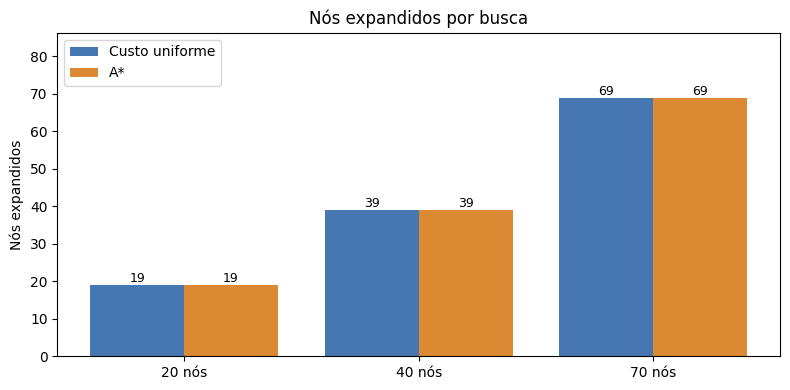

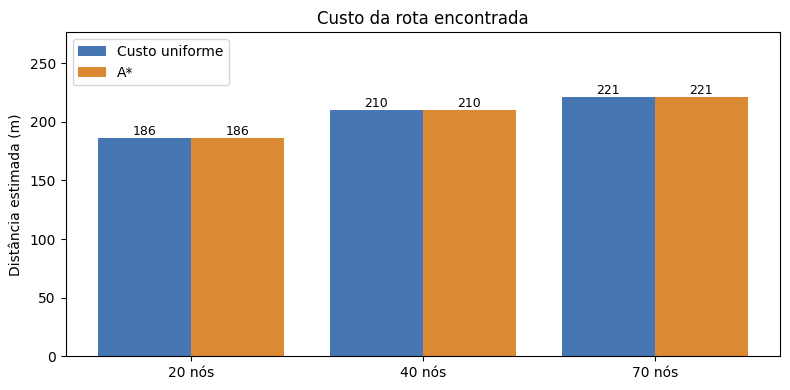

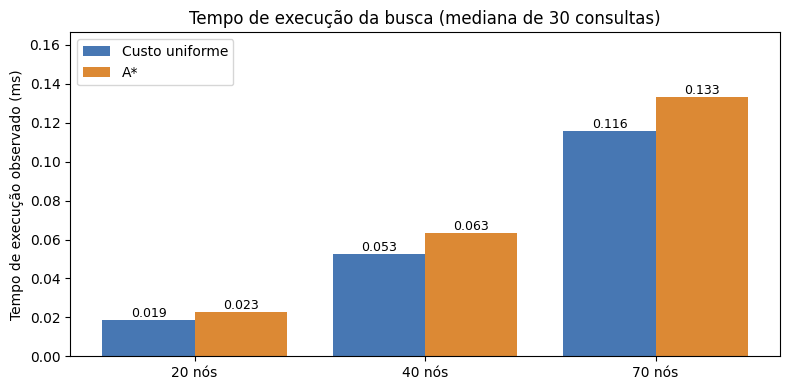

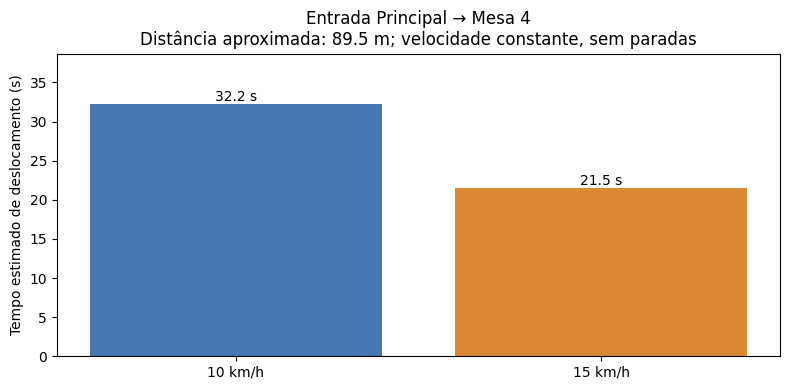

In [9]:
import matplotlib.pyplot as plt

for campo, titulo, unidade in [
    ("expandidos", "Nós expandidos por busca", "Nós expandidos"),
    ("custo_m", "Custo da rota encontrada", "Distância estimada (m)"),
    ("execucao_ms", "Tempo de execução da busca (mediana de 30 consultas)", "Tempo de execução observado (ms)"),
]:
    plt.figure(figsize=(8, 4))
    for algoritmo, deslocamento, cor in [("Custo uniforme", -0.2, "#4777b3"),
                                        ("A*", 0.2, "#dc8934")]:
        valores = [r[campo] for r in RESULTADOS if r["algoritmo"] == algoritmo]
        barras = plt.bar([x + deslocamento for x in range(3)], valores,
                        width=0.4, label=algoritmo, color=cor)
        for barra, valor in zip(barras, valores):
            texto = f"{valor:.3f}" if campo == "execucao_ms" else f"{valor:g}"
            plt.text(barra.get_x() + barra.get_width() / 2, valor, texto,
                     ha="center", va="bottom", fontsize=9)
    plt.xticks([0, 1, 2], ["20 nós", "40 nós", "70 nós"])
    plt.ylabel(unidade)
    plt.title(titulo)
    plt.margins(y=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig("comparacao_" + campo + ".png", dpi=150)
    plt.show()
    plt.close()

caminho, distancia = a_estrela(ORIGEM, DESTINO)
if caminho is not None:
    velocidades = [10, 15]
    tempos = [calcular_tempo(distancia, velocidade) for velocidade in velocidades]
    plt.figure(figsize=(8, 4))
    plt.bar(["10 km/h", "15 km/h"], tempos, color=["#4777b3", "#dc8934"])
    for x, segundos in enumerate(tempos):
        plt.text(x, segundos, f"{segundos:.1f} s", ha="center", va="bottom")
    plt.ylabel("Tempo estimado de deslocamento (s)")
    plt.title(f"{ORIGEM} → {DESTINO}\nDistância aproximada: {distancia:.1f} m; velocidade constante, sem paradas")
    plt.margins(y=0.2)
    plt.tight_layout()
    plt.savefig("tempo_deslocamento.png", dpi=150)
    plt.show()
    plt.close()

## 5.3 Fase 2 — aprendizado com dados sintéticos

Escolha autorizada pelo grupo: dados sintéticos. São 90 trechos × 2 cenários × 12 repetições = 2.160 linhas. Piso e porta são atributos fictícios sorteados por trecho; fluxo e obstáculo variam por observação. Nenhuma dessas características foi medida no campus. Não há simulação de movimento do carrinho.

Regra pública do alvo (s): distância × 3,6 / 10 × (1 + 0,15 × fluxo + 0,25 × piso irregular) + 3 × porta + 12 × obstáculo + ruído normal de desvio 0,8 s; mínimo 0,1 s. Semente 42. Obstáculo significa atraso no cenário fictício, não bloqueio inacessível. Tempos e previsões são SINTÉTICOS.

Não há faltantes ou linhas descartadas nesta geração. Imputação por mediana/moda, padronização e one-hot são ajustados dentro de cada divisão de treino via Pipeline. Nomes e identificador de trecho não entram no modelo. Reservamos 20% dos trechos para teste; comparamos regressão linear e árvore em validação cruzada de 5 grupos nos demais trechos. Selecionamos pelo MAE, avaliamos uma vez no teste reservado e só então reajustamos o modelo escolhido com todos os dados para uso da ferramenta.

A comparação mede MAE/RMSE em segundos e R². Os erros e o CSV são salvos em resultados_fase2. A função rota_tempo_previsto usa o mesmo laço A*, com pesos e heurística em segundos. Os dois sentidos têm o mesmo tempo por hipótese. A consulta usa fluxo 1/4 e obstáculo 0/1 para tranquilo/movimentado. A velocidade-base de 10 km/h faz parte da regra de geração; esta ferramenta não aceita outra velocidade.

O grafo de 90 nós possui um ciclo no pátio. A Fase 2 pode escolher outro caminho pelos custos previstos. As passagens dependem do espaço disponível entre mesas e cadeiras. Os testes locais não substituem a execução integral no Colab nem avaliam validade física.

In [10]:
%pip -q install numpy pandas scikit-learn

In [11]:
# FASE_2_SINTETICA: executada também dentro do notebook unificado.
import json
import random
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMENTE_DADOS = 42
PASTA_FASE2 = Path('resultados_fase2')
PASTA_FASE2.mkdir(exist_ok=True)


def gerar_dados_sinteticos():
    sorteio = random.Random(SEMENTE_DADOS)
    linhas = []
    for trecho, (origem, destino, distancia) in enumerate(LIGACOES):
        # Atributos fictícios: não descrevem portas/pisos observados no campus.
        piso = sorteio.choice(['regular', 'irregular'])
        porta = sorteio.choice([0, 1])
        for cenario in ['tranquilo', 'movimentado']:
            for repeticao in range(12):
                fluxo = sorteio.randint(0, 2) if cenario == 'tranquilo' else sorteio.randint(3, 5)
                obstaculo = int(sorteio.random() < (0.1 if cenario == 'tranquilo' else 0.4))
                base = distancia * 3.6 / 10
                tempo = (base * (1 + 0.15 * fluxo + 0.25 * (piso == 'irregular'))
                         + 3 * porta + 12 * obstaculo + sorteio.gauss(0, 0.8))
                linhas.append(dict(trecho=trecho, origem=origem, destino=destino,
                                   distancia_m=distancia, cenario=cenario, fluxo=fluxo,
                                   piso=piso, porta=porta, obstaculo=obstaculo,
                                   repeticao=repeticao, tempo_s=max(0.1, tempo),
                                   origem_do_dado='sintetico'))
    return pd.DataFrame(linhas)


NUMERICAS = ['distancia_m', 'fluxo', 'porta', 'obstaculo']
CATEGORICAS = ['piso', 'cenario']
ENTRADAS = NUMERICAS + CATEGORICAS


def preparar_modelo(nome):
    numericas = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    categorias = make_pipeline(SimpleImputer(strategy='most_frequent'),
                               OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    preparo = ColumnTransformer([('numericas', numericas, NUMERICAS),
                                 ('categorias', categorias, CATEGORICAS)])
    estimador = LinearRegression() if nome == 'regressao_linear' else DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=5, random_state=SEMENTE_DADOS)
    return make_pipeline(preparo, estimador)


def metricas_tempo(real, previsto):
    return dict(mae_s=float(mean_absolute_error(real, previsto)),
                rmse_s=float(np.sqrt(mean_squared_error(real, previsto))),
                r2=float(r2_score(real, previsto)))


DADOS_TEMPO = gerar_dados_sinteticos()
# Não há faltantes ou descartes na geração. A imputação é aprendida dentro de cada fold.
assert not DADOS_TEMPO.isna().any().any()
assert not DADOS_TEMPO.duplicated(['trecho', 'cenario', 'repeticao']).any()
assert (DADOS_TEMPO.tempo_s > 0).all()
DADOS_TEMPO.to_csv(PASTA_FASE2 / 'tempos_sinteticos.csv', index=False)

separador = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE_DADOS)
indices_treino, indices_teste = next(separador.split(DADOS_TEMPO, groups=DADOS_TEMPO.trecho))
treino = DADOS_TEMPO.iloc[indices_treino]
teste = DADOS_TEMPO.iloc[indices_teste]
assert set(treino.trecho).isdisjoint(teste.trecho)
COMPARACAO_MODELOS = []
for nome in ['regressao_linear', 'arvore_decisao']:
    previsto = cross_val_predict(preparar_modelo(nome), treino[ENTRADAS], treino.tempo_s,
                                 groups=treino.trecho, cv=GroupKFold(n_splits=5))
    previsto = np.maximum(0.1, previsto)
    COMPARACAO_MODELOS.append(dict(modelo=nome, **metricas_tempo(treino.tempo_s, previsto)))
MELHOR_MODELO = min(COMPARACAO_MODELOS, key=lambda r: r['mae_s'])['modelo']
modelo_avaliado = preparar_modelo(MELHOR_MODELO)
modelo_avaliado.fit(treino[ENTRADAS], treino.tempo_s)
previsoes_teste = np.maximum(0.1, modelo_avaliado.predict(teste[ENTRADAS]))
METRICAS_TESTE = metricas_tempo(teste.tempo_s, previsoes_teste)
erros = teste.copy()
erros['previsto_s'] = previsoes_teste
erros['erro_absoluto_s'] = abs(erros.tempo_s - erros.previsto_s)
erros.to_csv(PASTA_FASE2 / 'previsoes_teste.csv', index=False)
pd.DataFrame(COMPARACAO_MODELOS).to_csv(PASTA_FASE2 / 'validacao_cruzada.csv', index=False)
print('Dados SINTÉTICOS:', len(DADOS_TEMPO), 'linhas;', len(LIGACOES), 'trechos; 24 cenários/repetições por trecho.')
print('Validação cruzada por trecho (5 folds), apenas no treino:')
print(pd.DataFrame(COMPARACAO_MODELOS).to_string(index=False))
print('Escolhido pelo menor MAE de validação:', MELHOR_MODELO)
print('Teste reservado por trecho, usado somente depois da escolha:', METRICAS_TESTE)
print('Erro médio absoluto por cenário no teste:')
print(erros.groupby('cenario').erro_absoluto_s.mean())
print('Cinco maiores erros no teste:')
print(erros.nlargest(5, 'erro_absoluto_s')[['origem', 'destino', 'cenario', 'tempo_s', 'previsto_s', 'erro_absoluto_s']].to_string(index=False))
(PASTA_FASE2 / 'resumo.json').write_text(json.dumps(dict(
    semente=SEMENTE_DADOS, linhas=len(DADOS_TEMPO), trechos_treino=sorted(treino.trecho.unique().tolist()),
    trechos_teste=sorted(teste.trecho.unique().tolist()), validacao=COMPARACAO_MODELOS,
    escolhido=MELHOR_MODELO, teste=METRICAS_TESTE), ensure_ascii=False, indent=2))

# Reajuste final para uso da ferramenta. As métricas acima são anteriores a esse reajuste.
MODELO_TEMPO = preparar_modelo(MELHOR_MODELO)
MODELO_TEMPO.fit(DADOS_TEMPO[ENTRADAS], DADOS_TEMPO.tempo_s)


def prever_grafo_tempo(cenario):
    if cenario not in ['tranquilo', 'movimentado', 'cadeiras_no_patio']:
        raise ValueError('Cenário desconhecido.')
    atributos = DADOS_TEMPO.drop_duplicates('trecho')[ENTRADAS].reset_index(drop=True).copy()
    base = 'tranquilo' if cenario == 'cadeiras_no_patio' else cenario
    atributos['cenario'] = base
    atributos['fluxo'] = 1 if base == 'tranquilo' else 4
    atributos['obstaculo'] = 0 if base == 'tranquilo' else 1
    if cenario == 'cadeiras_no_patio':
        # Cenário didático: atraso no trecho A-B, sem alegar bloqueio real detectado.
        for indice, (origem, destino, _) in enumerate(LIGACOES):
            if {origem, destino} == {'Pátio - A', 'Pátio - B'}:
                atributos.loc[indice, ['cenario', 'fluxo', 'obstaculo']] = ['movimentado', 5, 1]
    tempos = np.maximum(0.1, MODELO_TEMPO.predict(atributos))
    assert len(tempos) == len(LIGACOES)
    grafo = {local: [] for local in LOCAIS}
    for (origem, destino, distancia), segundos in zip(LIGACOES, tempos):
        grafo[origem].append((destino, float(segundos)))
        grafo[destino].append((origem, float(segundos)))
    return grafo


def rota_tempo_previsto(origem: str, destino: str, cenario: str = 'tranquilo') -> str:
    """Calcula a rota de menor tempo previsto por modelo treinado em dados sintéticos.

    Args:
        origem: nome exato do local de partida
        destino: nome exato do local de chegada
        cenario: tranquilo, movimentado ou cadeiras_no_patio; cenários fictícios com base de 10 km/h
    """
    if origem not in LOCAIS or destino not in LOCAIS:
        return 'Erro: origem ou destino não existe no mapa.'
    if cenario not in ['tranquilo', 'movimentado', 'cadeiras_no_patio']:
        return 'Erro: cenário deve ser tranquilo, movimentado ou cadeiras_no_patio.'
    grafo = prever_grafo_tempo(cenario)
    # Referência em SEGUNDOS: nunca reutilizar a heurística antiga em metros.
    referencia = {local: buscar('Entrada Principal', local, grafo, False)[1] for local in LOCAIS}
    caminho, segundos, expandidos = buscar(origem, destino, grafo, True, referencia)
    if caminho is None:
        return 'Não existe caminho entre os locais.'
    return ('Caminho: ' + ' -> '.join(caminho) + f'. Tempo previsto: {segundos:.1f} s.'
            + ' Cenário SINTÉTICO: ' + cenario + '. Modelo: ' + MELHOR_MODELO
            + '. Sem validação de tempo no campus; conferir passagem entre móveis.')


for cenario in ['tranquilo', 'movimentado']:
    print(rota_tempo_previsto(ORIGEM, DESTINO, cenario))


def demonstrar_alternativa_patio():
    origem, destino = 'Mesa 1', 'Mesa 4'
    curto, metros = a_estrela(origem, destino)
    grafo = prever_grafo_tempo('cadeiras_no_patio')
    referencia = {local: buscar('Entrada Principal', local, grafo, False)[1] for local in LOCAIS}
    rapido, tempo, _ = buscar(origem, destino, grafo, True, referencia)
    tempo_curto = sum(dict(grafo[a])[b] for a, b in zip(curto, curto[1:]))
    metros_rapido = sum(dict(VIZINHOS[a])[b] for a, b in zip(rapido, rapido[1:]))
    resultado = dict(origem=origem, destino=destino, cenario='cadeiras_no_patio',
                     rota_distancia=curto, distancia_m=metros, tempo_rota_curta_s=tempo_curto,
                     rota_tempo=rapido, distancia_rota_tempo_m=metros_rapido, tempo_previsto_s=tempo,
                     mudou=curto != rapido, economia_prevista_s=tempo_curto - tempo)
    print('Demonstração SINTÉTICA; requer passagem física disponível:', resultado)
    (PASTA_FASE2 / 'demonstracao_patio.json').write_text(json.dumps(resultado, ensure_ascii=False, indent=2))
    return resultado


DEMONSTRACAO_PATIO = demonstrar_alternativa_patio()

FERRAMENTAS.append(rota_tempo_previsto)


Dados SINTÉTICOS: 2160 linhas; 90 trechos; 24 cenários/repetições por trecho.
Validação cruzada por trecho (5 folds), apenas no treino:
          modelo    mae_s   rmse_s       r2
regressao_linear 1.037762 1.513364 0.969266
  arvore_decisao 1.158831 1.906970 0.951200
Escolhido pelo menor MAE de validação: regressao_linear
Teste reservado por trecho, usado somente depois da escolha: {'mae_s': 1.0140017490453384, 'rmse_s': 1.5207300957959842, 'r2': 0.9695809215654181}
Erro médio absoluto por cenário no teste:
cenario
movimentado    1.048966
tranquilo      0.979037
Name: erro_absoluto_s, dtype: float64
Cinco maiores erros no teste:
           origem      destino     cenario   tempo_s  previsto_s  erro_absoluto_s
Entrada Principal Eixo - Norte   tranquilo 21.250926   29.802395         8.551469
Entrada Principal Eixo - Norte   tranquilo 21.514941   29.802395         8.287454
Entrada Principal Eixo - Norte   tranquilo 21.692708   29.802395         8.109688
Entrada Principal Eixo - Norte   tr

## 6. Qwen do gabarito
A partir daqui é necessário instalar `transformers` e baixar o modelo público. No Colab, use uma GPU T4 se disponível. As funções anteriores já calculam os resultados sem o LLM.

In [12]:
%pip -q install transformers

In [13]:
import json
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

if torch.cuda.is_available():
    dispositivo = "cuda"
else:
    dispositivo = "cpu"
print("Dispositivo:", dispositivo)

nome_qwen = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizador_qwen = AutoTokenizer.from_pretrained(nome_qwen)
if dispositivo == "cuda":
    qwen = AutoModelForCausalLM.from_pretrained(nome_qwen, dtype=torch.float16).to(dispositivo)
else:
    qwen = AutoModelForCausalLM.from_pretrained(nome_qwen, dtype=torch.float32)
qwen.eval()


def conversar(mensagens, ferramentas=None, max_tokens=200):
    entrada = tokenizador_qwen.apply_chat_template(
        mensagens, tools=ferramentas, add_generation_prompt=True,
        return_tensors="pt", return_dict=True
    ).to(dispositivo)
    with torch.no_grad():
        saida = qwen.generate(**entrada, max_new_tokens=max_tokens, do_sample=False)
    tamanho_da_pergunta = entrada["input_ids"].shape[-1]
    return tokenizador_qwen.decode(saida[0][tamanho_da_pergunta:], skip_special_tokens=True)


print("Qwen carregado.")

Dispositivo: cuda


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen carregado.


## 7. Agente com ferramentas — mesmo ciclo do gabarito

In [14]:
REGRAS = (
    "Para pedidos de tempo aprendido ou cenário sintético tranquilo/movimentado, use rota_tempo_previsto. Para atraso hipotético por cadeiras no pátio, use cenario=cadeiras_no_patio. "
    "Para distância e tempo a velocidade constante explícita, use ferramenta_do_trio. Não confunda os dois tempos. "
    "Você ajuda a encontrar rotas no térreo do IESB. "
    "Para perguntas sobre caminhos, custos e locais vizinhos, use as ferramentas. "
    "Nunca invente rotas, distâncias em metros ou acessos: use apenas o resultado das ferramentas. "
    "As distâncias são aproximadas. ferramenta_do_trio calcula tempo a velocidade constante, sem paradas; use velocidade_kmh quando informada. rota_tempo_previsto usa dados sintéticos, incluindo atrasos hipotéticos, e não detecta obstáculos físicos. "
    "Responda em português, de forma curta. "
    "Nomes válidos dos locais: " + ", ".join(LOCAIS) + "."
)


def extrair_json(texto):
    inicio = texto.find("{")
    fim = texto.rfind("}")
    if inicio == -1 or fim == -1:
        return None
    try:
        return json.loads(texto[inicio:fim + 1])
    except (ValueError, TypeError):
        return None


def ler_pedido_de_ferramenta(resposta):
    if "<tool_call>" not in resposta:
        return None
    return extrair_json(resposta)


def executar(pedido):
    if not isinstance(pedido, dict):
        return "Erro: pedido de ferramenta inválido."
    nome = pedido.get("name")
    argumentos = pedido.get("arguments", {})
    if not isinstance(argumentos, dict):
        return "Erro: argumentos da ferramenta inválidos."
    if nome == "rota_tempo_previsto":
        return rota_tempo_previsto(argumentos.get("origem"), argumentos.get("destino"),
                                   argumentos.get("cenario", "tranquilo"))
    if nome == "calcular_rota":
        return calcular_rota(argumentos.get("origem"), argumentos.get("destino"),
                             argumentos.get("velocidade_kmh", VELOCIDADE_KMH))
    if nome == "ferramenta_do_trio":
        return ferramenta_do_trio(argumentos.get("origem"), argumentos.get("destino"),
                             argumentos.get("velocidade_kmh", VELOCIDADE_KMH))
    if nome == "listar_vizinhos":
        return listar_vizinhos(argumentos.get("local"))
    return "Erro: a ferramenta " + str(nome) + " não existe."


def agente(pergunta, mostrar=True, retornar_detalhes=False):
    mensagens = [
        {"role": "system", "content": REGRAS},
        {"role": "user", "content": pergunta},
    ]
    chamadas = []
    for passo in range(3):
        resposta = conversar(mensagens, FERRAMENTAS)
        pedido = ler_pedido_de_ferramenta(resposta)
        if pedido is None:
            if retornar_detalhes:
                return {"resposta": resposta, "chamadas": chamadas}
            return resposta
        resultado = executar(pedido)
        chamadas.append({"pedido": pedido, "resultado": resultado})
        if mostrar:
            print("   [ferramenta]", pedido.get("name"), pedido.get("arguments"))
            print("   [resultado ]", resultado)
        mensagens.append({"role": "assistant", "content": resposta})
        mensagens.append({"role": "tool", "content": resultado})
    resposta = "Não consegui concluir em 3 passos."
    if retornar_detalhes:
        return {"resposta": resposta, "chamadas": chamadas}
    return resposta

## 8. Perguntas e descrição da ferramenta

In [15]:
from transformers.utils import get_json_schema

print(json.dumps(get_json_schema(ferramenta_do_trio), indent=1, ensure_ascii=False))

perguntas = [
    "Como vou da Entrada Principal até a Mesa 4 e quanto tempo levo a 10 km/h?",
    "Qual a distância de B-04 até I-05 e o tempo a 15 km/h?",
    "Quais locais estão ligados ao Pátio/Direito?",
]
for pergunta in perguntas:
    print("PERGUNTA:", pergunta)
    print("RESPOSTA:", agente(pergunta))
    print()

{
 "type": "function",
 "function": {
  "name": "ferramenta_do_trio",
  "description": "Consulta a rota A* e retorna distância aproximada e tempo estimado de deslocamento.",
  "parameters": {
   "type": "object",
   "properties": {
    "origem": {
     "type": "string",
     "description": "nome exato do local de partida na lista de locais"
    },
    "destino": {
     "type": "string",
     "description": "nome exato do local de chegada na lista de locais"
    },
    "velocidade_kmh": {
     "type": "number",
     "description": "velocidade constante em km/h, positiva; omitir para usar a configuração"
    }
   },
   "required": [
    "origem",
    "destino"
   ]
  },
  "return": {
   "type": "string"
  }
 }
}
PERGUNTA: Como vou da Entrada Principal até a Mesa 4 e quanto tempo levo a 10 km/h?
   [ferramenta] rota_tempo_previsto {'origem': 'Entrada Principal', 'destino': 'Mesa 4', 'cenario': 'tranqüilo'}
   [resultado ] Erro: cenário deve ser tranquilo, movimentado ou cadeiras_no_patio.

## 8.1 Interface opcional por texto
A função abaixo permite digitar vários pedidos. Ela não é iniciada automaticamente, para que a execução completa do notebook não fique bloqueada esperando entrada. Depois de carregar o Qwen, execute `conversa_interativa()` em uma célula separada e digite `sair` para encerrar.

In [16]:
def conversa_interativa():
    print("Conversa iniciada. Digite 'sair' para encerrar.")
    while True:
        pergunta = input("Você: " ).strip()
        if pergunta.lower() == "sair":
            print("Conversa encerrada.")
            break
        if pergunta == "":
            print("Digite uma pergunta ou 'sair'.")
            continue
        print("Agente:", agente(pergunta))

## 9. Avaliação do agente — 23 casos definidos antes da execução
São mantidos os 15 casos anteriores e acrescentados 7 pedidos de tempo aprendido (tranquilo, movimentado e cadeiras_no_patio, ida/volta, cenário padrão, lanchonetes e origem igual ao destino) e 1 contraste com velocidade constante de 15 km/h.

Antes de qualquer inferência da bateria, são preparados ferramenta, argumentos, resultado da ferramenta e referência de caminho/custo com custo uniforme. As verificações automáticas separam ferramenta, argumentos (incluindo extras), quantidade de chamadas, resultado e conteúdo mínimo da resposta. Erros de execução são registrados sem interromper os demais casos.

A triagem de conteúdo verifica locais na ordem, valores/unidades e indicação de dados sintéticos. Ela é conservadora e pode rejeitar paráfrases corretas; também não prova ausência de contradições ou fatos inventados. Por isso resposta_fiel fica pendente de revisão humana, inclusive nos casos sem ferramenta. Nenhum sucesso do Qwen foi preenchido antecipadamente.


In [17]:
CASOS = [
    {"id": 1, "pergunta": "Como vou da Entrada Principal até a Mesa 2 a 10 km/h?",
     "ferramenta": "ferramenta_do_trio", "argumentos": {"origem": "Entrada Principal", "destino": "Mesa 2", "velocidade_kmh": 10}},
    {"id": 2, "pergunta": "Qual é a rota de B-04 para I-05 a 15 km/h?",
     "ferramenta": "ferramenta_do_trio", "argumentos": {"origem": "B-04", "destino": "I-05", "velocidade_kmh": 15}},
    {"id": 3, "pergunta": "Saindo da Biblioteca, como chego à C-02 a 10 km/h?",
     "ferramenta": "ferramenta_do_trio", "argumentos": {"origem": "Biblioteca", "destino": "C-02", "velocidade_kmh": 10}},
    {"id": 4, "pergunta": "Mostre o caminho de D-01 até WC Feminino Design a 10 km/h.",
     "ferramenta": "ferramenta_do_trio", "argumentos": {"origem": "D-01", "destino": "WC Feminino Design", "velocidade_kmh": 10}},
    {"id": 5, "pergunta": "Como ir de J-06 para C-06 a 10 km/h?",
     "ferramenta": "ferramenta_do_trio", "argumentos": {"origem": "J-06", "destino": "C-06", "velocidade_kmh": 10}},
    {"id": 6, "pergunta": "Calcule a rota da Mesa 1 à Mesa 4 a 10 km/h.",
     "ferramenta": "ferramenta_do_trio", "argumentos": {"origem": "Mesa 1", "destino": "Mesa 4", "velocidade_kmh": 10}},
    {"id": 7, "pergunta": "Qual o caminho de WC Cinema até Anexo Creche a 10 km/h?",
     "ferramenta": "ferramenta_do_trio", "argumentos": {"origem": "WC Cinema", "destino": "Anexo Creche", "velocidade_kmh": 10}},
    {"id": 8, "pergunta": "Quero ir do Bloco I até Café Mania a 15 km/h. Qual a rota?",
     "ferramenta": "ferramenta_do_trio", "argumentos": {"origem": "Bloco I", "destino": "Café Mania", "velocidade_kmh": 15}},
    {"id": 9, "pergunta": "Quais locais estão ligados diretamente ao Pátio/Direito?",
     "ferramenta": "listar_vizinhos", "argumentos": {"local": "Pátio/Direito"}},
    {"id": 10, "pergunta": "O que há ao lado do Corredor Design?",
     "ferramenta": "listar_vizinhos", "argumentos": {"local": "Corredor Design"}},
    {"id": 11, "pergunta": "Liste os vizinhos diretos de Cinema.",
     "ferramenta": "listar_vizinhos", "argumentos": {"local": "Cinema"}},
    {"id": 12, "pergunta": "Quais pontos têm ligação direta com Corredor I/J?",
     "ferramenta": "listar_vizinhos", "argumentos": {"local": "Corredor I/J"}},
    {"id": 13, "pergunta": "Bom dia!", "ferramenta": None, "argumentos": {}},
    {"id": 14, "pergunta": "Obrigado pela ajuda!", "ferramenta": None, "argumentos": {}},
    {"id": 15, "pergunta": "Qual é a capital do Brasil?", "ferramenta": None, "argumentos": {}},
    {"id":16,"pergunta":"Qual a rota e o tempo aprendido da Mesa 1 até a Mesa 4 no cenário tranquilo?","ferramenta":"rota_tempo_previsto","argumentos":{"origem":"Mesa 1","destino":"Mesa 4","cenario":"tranquilo"}},
    {"id":17,"pergunta":"Qual a rota e o tempo previsto da Mesa 1 até a Mesa 4 no cenário movimentado?","ferramenta":"rota_tempo_previsto","argumentos":{"origem":"Mesa 1","destino":"Mesa 4","cenario":"movimentado"}},
    {"id":18,"pergunta":"Qual o caminho da Mesa 1 à Mesa 4 no cenário sintético de cadeiras no pátio?","ferramenta":"rota_tempo_previsto","argumentos":{"origem":"Mesa 1","destino":"Mesa 4","cenario":"cadeiras_no_patio"}},
    {"id":19,"pergunta":"Preveja a rota da Mesa 1 até Café Mania com atraso hipotético por cadeiras no pátio.","ferramenta":"rota_tempo_previsto","argumentos":{"origem":"Mesa 1","destino":"Café Mania","cenario":"cadeiras_no_patio"}},
    {"id":20,"pergunta":"Qual o tempo aprendido de Easy Smart até Café Mania usando o cenário padrão?","ferramenta":"rota_tempo_previsto","argumentos":{"origem":"Easy Smart","destino":"Café Mania"}},
    {"id":21,"pergunta":"Calcule o tempo previsto saindo da Mesa 4 e chegando à própria Mesa 4 no cenário movimentado.","ferramenta":"rota_tempo_previsto","argumentos":{"origem":"Mesa 4","destino":"Mesa 4","cenario":"movimentado"}},
    {"id":22,"pergunta":"No cenário sintético de cadeiras no pátio, como vou da Mesa 4 à Mesa 1 e qual o tempo previsto?","ferramenta":"rota_tempo_previsto","argumentos":{"origem":"Mesa 4","destino":"Mesa 1","cenario":"cadeiras_no_patio"}},
    {"id":23,"pergunta":"Da Mesa 1 à Mesa 4, calcule a rota e o tempo a velocidade constante de 15 km/h, sem usar previsão aprendida.","ferramenta":"ferramenta_do_trio","argumentos":{"origem":"Mesa 1","destino":"Mesa 4","velocidade_kmh":15}},
]

# Funções incorporadas à seção 9 do notebook; sem classes próprias.
import re
import unicodedata


def normalizar_argumentos(nome, argumentos):
    if not isinstance(argumentos, dict):
        return None
    normalizados = argumentos.copy()
    if nome == 'ferramenta_do_trio':
        normalizados.setdefault('velocidade_kmh', VELOCIDADE_KMH)
    if nome == 'rota_tempo_previsto':
        normalizados.setdefault('cenario', 'tranquilo')
    # Preserva parâmetros extras: ignorá-los esconderia um erro do LLM.
    return normalizados


def preparar_resultado_esperado(caso):
    nome, argumentos = caso['ferramenta'], caso['argumentos']
    if nome is None:
        return None, dict(caminho=[], vizinhos=[], valores=[], sintetico=False)
    resultado = executar({'name': nome, 'arguments': argumentos})
    assert not resultado.startswith('Erro:'), 'Referência inválida: ' + str(caso['id'])
    referencia = dict(caminho=[], vizinhos=[], valores=[], sintetico=False)
    if nome == 'listar_vizinhos':
        referencia['vizinhos'] = [v for v, _ in VIZINHOS[argumentos['local']]]
    else:
        grafo = VIZINHOS
        if nome == 'rota_tempo_previsto':
            grafo = prever_grafo_tempo(argumentos.get('cenario', 'tranquilo'))
            referencia['sintetico'] = True
        # Custo uniforme como referência independente da heurística do A*.
        caminho, custo, _ = buscar(argumentos['origem'], argumentos['destino'], grafo, False)
        referencia['caminho'] = caminho
        if nome == 'ferramenta_do_trio':
            segundos = calcular_tempo(custo, argumentos.get('velocidade_kmh', VELOCIDADE_KMH))
            referencia['valores'] = [f'{custo:.1f} m', f'{segundos:.1f} s']
        else:
            referencia['valores'] = [f'{custo:.1f} s']
    return resultado, referencia


def normalizar_texto(texto):
    texto = unicodedata.normalize('NFD', texto.lower())
    texto = ''.join(letra for letra in texto if unicodedata.category(letra) != 'Mn')
    texto = texto.replace(',', '.')
    texto = re.sub(r'\b(metros?|segundos?)\b', lambda m: 'm' if m[0].startswith('metro') else 's', texto)
    return ' '.join(texto.split())


def conferir_conteudo(resposta, referencia):
    # Triagem literal conservadora; a revisão humana continua obrigatória.
    texto = normalizar_texto(resposta)
    posicao = 0
    for local in referencia['caminho']:
        achado = texto.find(normalizar_texto(local), posicao)
        if achado < 0:
            return False
        posicao = achado + len(normalizar_texto(local))
    if not all(normalizar_texto(v) in texto for v in referencia['vizinhos']):
        return False
    for valor in referencia['valores']:
        numero, unidade = valor.split()
        # Aceita 30 s, 30.0 s e 30,0 segundos; rejeita 130 s como se fosse 30 s.
        numero = numero[:-2] + r'(?:\.0)?' if numero.endswith('.0') else re.escape(numero)
        if re.search(r'(?<![\d.])' + numero + r'\s*' + unidade + r'\b', texto) is None:
            return False
    return not referencia['sintetico'] or 'sintetic' in texto


def avaliar_caso(caso):
    inicio = perf_counter()
    erro = None
    try:
        detalhes = agente(caso['pergunta'], mostrar=False, retornar_detalhes=True)
    except Exception as falha:
        detalhes = {'resposta': '', 'chamadas': []}
        erro = type(falha).__name__ + ': ' + str(falha)
    duracao_s = perf_counter() - inicio
    chamadas = detalhes['chamadas']
    primeira = chamadas[0] if chamadas else None
    escolhida = primeira['pedido'].get('name') if primeira else None
    recebidos = primeira['pedido'].get('arguments', {}) if primeira else {}
    ferramenta_ok = erro is None and escolhida == caso['ferramenta']
    argumentos_ok = ferramenta_ok and normalizar_argumentos(escolhida, recebidos) == normalizar_argumentos(caso['ferramenta'], caso['argumentos'])
    quantidade_ok = len(chamadas) == (0 if caso['ferramenta'] is None else 1)
    resposta = detalhes['resposta']
    terminou = bool(resposta.strip()) and '<tool_call>' not in resposta and resposta != 'Não consegui concluir em 3 passos.'
    resultado_ok = ferramenta_ok and argumentos_ok and quantidade_ok and terminou
    if caso['ferramenta'] is not None:
        resultado_ok = resultado_ok and primeira['resultado'] == caso['resultado_esperado']
        conteudo_ok = resultado_ok and conferir_conteudo(resposta, caso['referencia'])
    else:
        conteudo_ok = None  # Saudação e fora de escopo exigem julgamento humano.
    return dict(id=caso['id'], pergunta=caso['pergunta'], ferramenta=ferramenta_ok,
                argumentos=argumentos_ok, chamadas_esperadas=quantidade_ok,
                resultado_valido=resultado_ok, conteudo_automatico=conteudo_ok,
                resposta_fiel=None, revisao='pendente', justificativa_revisao='',
                duracao_s=duracao_s, escolhida=escolhida, recebidos=recebidos,
                chamadas=chamadas, resposta=resposta, erro=erro)


# Todas as referências são produzidas antes da primeira inferência da bateria.
for caso in CASOS:
    resultado, referencia = preparar_resultado_esperado(caso)
    caso['resultado_esperado'] = resultado
    caso['referencia'] = referencia
    caso['criterio_manual'] = (
        'Conferir caminho na ordem, números/unidades e ausência de locais ou fatos inventados. '
        'Em tempo aprendido, identificar dados sintéticos e não afirmar que detectou cadeiras. '
        'Em vizinhos, conferir lista sem acréscimos. Em saudação/fora de escopo, não inventar rota.'
    )
    print(caso['id'], '|', caso['ferramenta'], '|', caso['argumentos'], '|', resultado)


1 | ferramenta_do_trio | {'origem': 'Entrada Principal', 'destino': 'Mesa 2', 'velocidade_kmh': 10} | Caminho: Entrada Principal -> Eixo - Norte -> Pátio/Direito -> Pátio - B -> Mesa 2. Distância aproximada: 107.5 m. Velocidade constante: 10 km/h. Tempo estimado: 38.7 s (0.65 min), sem paradas.
2 | ferramenta_do_trio | {'origem': 'B-04', 'destino': 'I-05', 'velocidade_kmh': 15} | Caminho: B-04 -> Corredor Bloco B - 01/04 -> Corredor Bloco B - 02/05 -> Corredor Bloco B - 03/06 -> Corredor Bloco B -> Eixo - Bloco B -> Eixo - Bloco C -> Acesso Lateral I/J -> Corredor I/J -> Corredor I/J - WC I -> Corredor I/J - I-03/06 -> Corredor I/J - I-02/05 -> I-05. Distância aproximada: 120.0 m. Velocidade constante: 15 km/h. Tempo estimado: 28.8 s (0.48 min), sem paradas.
3 | ferramenta_do_trio | {'origem': 'Biblioteca', 'destino': 'C-02', 'velocidade_kmh': 10} | Caminho: Biblioteca -> Eixo - Norte -> Eixo - Design -> Eixo - Bloco C -> Corredor Bloco C -> Corredor Bloco C - 03/06 -> Corredor Bloco C

### 9.1 Executar e guardar a avaliação real
A célula seguinte chama o Qwen nos 23 casos e salva referências, chamadas, respostas, erros e durações em uma pasta exclusiva por execução. Preencha resposta_fiel (true/false), justificativa e revisor em revisao_manual.json somente depois de comparar cada resposta de resultados.json com casos_esperados.json. Preserve os resultados brutos. Não confunda a triagem automática com uma taxa de fidelidade validada. A latência é por pedido completo, sem o download e carregamento do modelo.

In [18]:
# Executar somente após carregar o Qwen real; não usar respostas artificiais nesta célula.
from datetime import datetime, timezone
from importlib.metadata import version

PASTA_AVALIACAO = Path('resultados_agente') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
PASTA_AVALIACAO.mkdir(parents=True, exist_ok=False)
metadados = dict(modelo=nome_qwen, revisao_modelo=getattr(qwen.config, '_commit_hash', None),
                 dispositivo=dispositivo, transformers=version('transformers'),
                 torch=version('torch'), regras=REGRAS, quantidade_casos=len(CASOS),
                 velocidade_padrao_kmh=VELOCIDADE_KMH, tipo_execucao='Qwen real',
                 geracao='do_sample=False; max_new_tokens=200; até 3 passos',
                 nos=LOCAIS, ligacoes=LIGACOES, modelo_custo=MELHOR_MODELO,
                 semente_dados=SEMENTE_DADOS)
(PASTA_AVALIACAO / 'metadados.json').write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding='utf-8')
(PASTA_AVALIACAO / 'casos_esperados.json').write_text(json.dumps(CASOS, ensure_ascii=False, indent=2), encoding='utf-8')

AVALIACOES = []
for caso in CASOS:
    avaliacao = avaliar_caso(caso)
    AVALIACOES.append(avaliacao)
    # Salva após cada caso para preservar o trabalho se a sessão for interrompida.
    (PASTA_AVALIACAO / 'resultados.json').write_text(json.dumps(AVALIACOES, ensure_ascii=False, indent=2), encoding='utf-8')
    print(avaliacao)

resumo = dict(executados=len(AVALIACOES), fidelidade_manual='pendente', criterios={})
for criterio in ['ferramenta', 'argumentos', 'chamadas_esperadas', 'resultado_valido', 'conteudo_automatico']:
    aplicaveis = [a for a in AVALIACOES if a[criterio] is not None]
    acertos = sum(a[criterio] for a in aplicaveis)
    resumo['criterios'][criterio] = dict(acertos=acertos, total=len(aplicaveis))
    print(criterio, ':', acertos, 'de', len(aplicaveis))
resumo['duracao_mediana_s'] = median(a['duracao_s'] for a in AVALIACOES)
(PASTA_AVALIACAO / 'resumo.json').write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding='utf-8')
revisao = [dict(id=a['id'], resposta_fiel=None, justificativa='', revisor='',
                criterio=CASOS[i]['criterio_manual']) for i, a in enumerate(AVALIACOES)]
(PASTA_AVALIACAO / 'revisao_manual.json').write_text(json.dumps(revisao, ensure_ascii=False, indent=2), encoding='utf-8')
print('Revisão humana da fidelidade pendente. Evidências salvas em:', PASTA_AVALIACAO)


{'id': 1, 'pergunta': 'Como vou da Entrada Principal até a Mesa 2 a 10 km/h?', 'ferramenta': True, 'argumentos': True, 'chamadas_esperadas': True, 'resultado_valido': True, 'conteudo_automatico': True, 'resposta_fiel': None, 'revisao': 'pendente', 'justificativa_revisao': '', 'duracao_s': 9.388751903000184, 'escolhida': 'ferramenta_do_trio', 'recebidos': {'origem': 'Entrada Principal', 'destino': 'Mesa 2', 'velocidade_kmh': 10}, 'chamadas': [{'pedido': {'name': 'ferramenta_do_trio', 'arguments': {'origem': 'Entrada Principal', 'destino': 'Mesa 2', 'velocidade_kmh': 10}}, 'resultado': 'Caminho: Entrada Principal -> Eixo - Norte -> Pátio/Direito -> Pátio - B -> Mesa 2. Distância aproximada: 107.5 m. Velocidade constante: 10 km/h. Tempo estimado: 38.7 s (0.65 min), sem paradas.'}], 'resposta': 'Você pode seguir este caminho: Entrada Principal -> Eixo - Norte -> Pátio/Direito -> Pátio - B -> Mesa 2. A distância é de aproximadamente 107.5 metros. Com uma velocidade constante de 10 km/h, o t

## Limites e próximos passos
Este notebook reúne o código atual dos Marcos 1 e 2. A seção 5.3 treina dois modelos com dados sintéticos e integra o escolhido ao A*. Ainda faltam a avaliação do Qwen incluindo a nova ferramenta, a execução integral no Colab e os relatórios finais. A fórmula distância/velocidade permanece como cálculo separado da previsão aprendida. Consulte `O_QUE_FALTA.md`.

O grafo agora divide os corredores em pontos sucessivos, agrupando portas próximas. O pátio tem trajetos alternativos condicionados à disposição de mesas e cadeiras; o programa não detecta bloqueios físicos. As posições e distâncias continuam aproximadas. As ligações e as distâncias precisam ser revisadas com medições para representar o campus com maior fidelidade.

O Qwen é executado localmente na sessão e não faz chamada a uma API paga nem usa chave escrita no código. Isso não significa custo zero: há tempo de inferência, consumo de memória e uso de CPU/GPU, que dependem do ambiente do Colab. A avaliação registra a duração por caso. Depois da execução real, o relatório deve discutir respostas inventadas, chamadas incorretas, pedidos fora do mapa e o efeito desses custos computacionais.